# Averaged velocity

The conservative velocity `cflux` of the annulus (off-centre hole: thick tissue on the left, thin on the right), averaged over one heartbeat ($t$ from 2 to 3 s), for both models.

**Our loading:** the cavity pressure pulses, $p_c = 133.3\,(1 - \cos 2\pi t)/2$ Pa, and the outer wall is at 0 Pa (`run_biot.py`).

In [1]:
from pathlib import Path
import subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
import dolfinx
import biotx

results = Path("results")
for script, name in (("run_biot.py", "annulus_biot3"), ("run_biot_transmantle.py", "annulus_biot3_transmantle")):
    if not (results / f"{name}_fields.npz").exists():       # run Biot once (about 1.5 minutes each)
        subprocess.run([sys.executable, script], check=True)

In [2]:
q = {m: biotx.load_fields(results / f"annulus_{m}_fields.npz").average("cflux", 2.0, 3.0)
     for m in ("biot2", "biot3")}

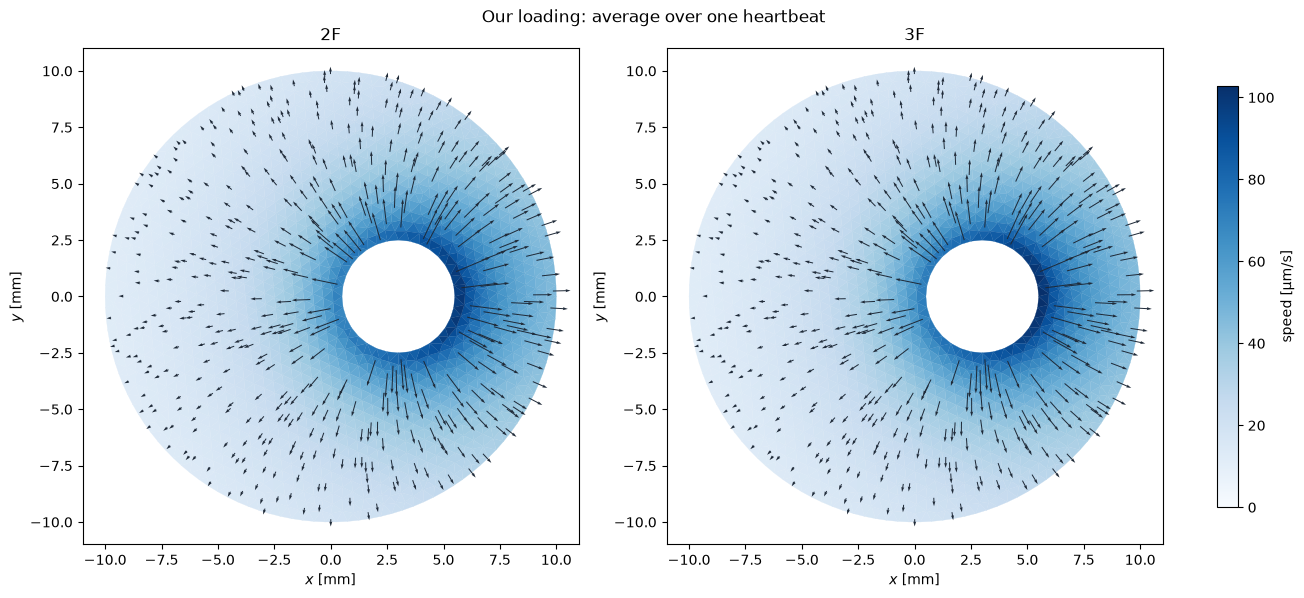

In [3]:
def at_cells(f):
    """Cell polygons (mm) and the field at the cell centres."""
    mesh = f.function_space.mesh
    cells = np.arange(mesh.topology.index_map(2).size_local, dtype=np.int32)
    centres = dolfinx.mesh.compute_midpoints(mesh, 2, cells)
    polys = mesh.geometry.x[mesh.geometry.dofmaps[0][cells], :2] * 1e3
    return polys, centres[:, :2] * 1e3, f.eval(centres, cells)


def plot(fields, titles, suptitle):
    """Speed (colour, one scale) and direction (arrows) of each field, side by side."""
    data = [at_cells(f) for f in fields]
    vmax = max(np.linalg.norm(v, axis=1).max() for _, _, v in data) * 1e6
    fig, axes = plt.subplots(1, len(fields), figsize=(13, 5.8), layout="constrained")
    for ax, title, (polys, x, v) in zip(axes, titles, data):
        speed = np.linalg.norm(v, axis=1) * 1e6              # µm/s
        pc = PolyCollection(polys, array=speed, cmap="Blues", clim=(0, vmax), edgecolors="face", linewidths=0.2)
        ax.add_collection(pc)
        k = slice(None, None, 6)                              # one arrow every 6 cells
        ax.quiver(x[k, 0], x[k, 1], v[k, 0], v[k, 1], color="#1f2a38", width=0.002)
        ax.set_aspect("equal")
        ax.autoscale_view()
        ax.set(title=title, xlabel="$x$ [mm]", ylabel="$y$ [mm]")
    fig.colorbar(pc, ax=axes, shrink=0.85, label="speed [µm/s]")
    fig.suptitle(suptitle)
    plt.show()


plot(list(q.values()), ["2F", "3F"], "Our loading: average over one heartbeat")

## Transmantle loading

Both walls pulse, $p = 947 + 160.5 \sin 2\pi t$ Pa on the outer wall and $947 + 162.1 \sin 2\pi t$ Pa in the cavity, so the difference between them (the transmantle pressure) is only $1.6 \sin 2\pi t$ Pa, with zero mean. At the cavity the solid feels $-\alpha p\,n$. The 947 Pa baseline is a static equilibrium, so only the oscillation is solved (`run_biot_transmantle.py`).

The model is linear: the period average of the response is the response to the period-averaged loading, which here is a uniform pressure, so **no net flow**. The fluid only moves back and forth. Below: the size of the average, and the instantaneous velocity at the moment of largest flow.

biot2: largest speed over the period 9.6e-06 m/s; largest speed of the period average 1.5e-10 m/s
biot3: largest speed over the period 8.3e-06 m/s; largest speed of the period average 1.4e-10 m/s


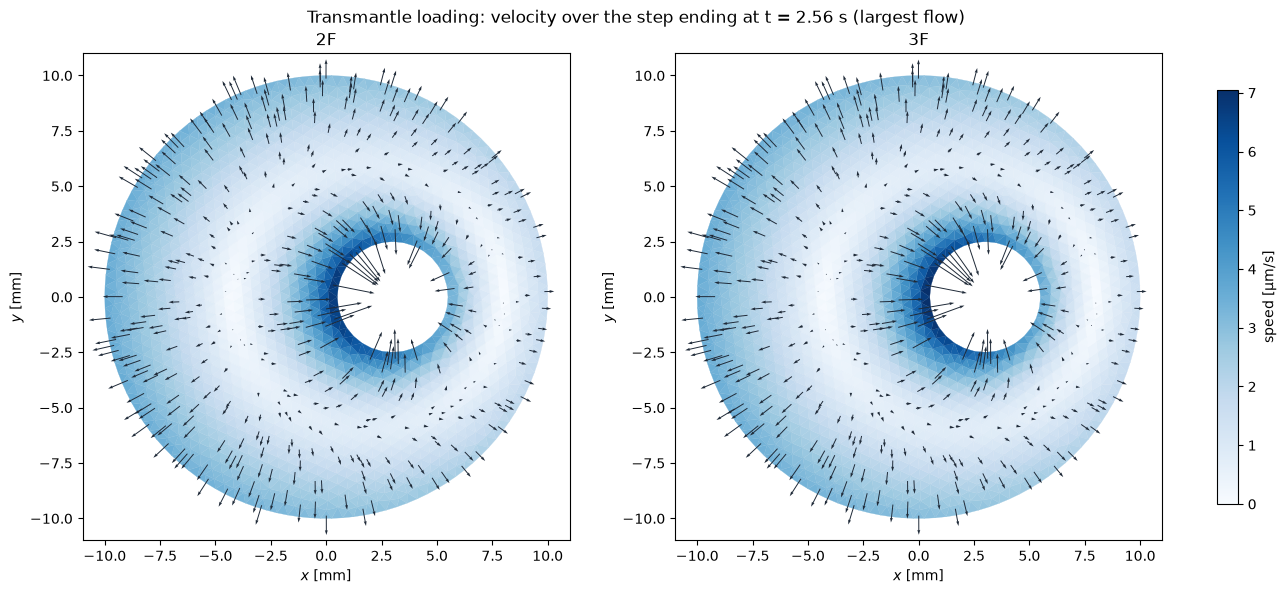

In [4]:
fl_m = {m: biotx.load_fields(results / f"annulus_{m}_transmantle_fields.npz") for m in ("biot2", "biot3")}
for m, fl in fl_m.items():
    avg = np.abs(fl.average("cflux", 2.0, 3.0).x.array).max()
    peak = max(np.abs(fl.function("cflux", i).x.array).max() for i in range(1, len(fl.snap_t)))
    print(f"{m}: largest speed over the period {peak:.1e} m/s; largest speed of the period average {avg:.1e} m/s")

fl = fl_m["biot2"]                                          # the moment of largest flow (2F)
i = max(range(1, len(fl.snap_t)), key=lambda i: np.abs(fl.function("cflux", i).x.array).max())
plot([fl_m[m].function("cflux", i) for m in ("biot2", "biot3")], ["2F", "3F"],
     f"Transmantle loading: velocity over the step ending at t = {fl.snap_t[i]:.2f} s (largest flow)")